In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

DATA_DIR=Path(r"D:\VScode\TMDB_csv_cleaned_file.csv")


Caste=pd.read_csv(DATA_DIR/"caste_cleaned.csv")
Crew=pd.read_csv(DATA_DIR/"crew_cleaned.csv")
Genres=pd.read_csv(DATA_DIR/"genres_cleaned.csv")
Movie_genres=pd.read_csv(DATA_DIR/"Movie_genres_cleaned.csv")
Movie_keywords=pd.read_csv(DATA_DIR/"movie_keywords_cleaned.csv")
Movies=pd.read_csv(DATA_DIR/"movies_cleaned.csv")


print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
print("Dataset shape:", Movies.shape)
print("Column names:", Movies.columns.tolist())


Dataset shape: (2503, 15)
Column names: ['movie_id', 'title', 'original_language', 'release_date', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'overview', 'day', 'month', 'year']


In [4]:
print(Movies.head())

   movie_id            title original_language release_date  runtime  \
0    157336     Interstellar                en   05-11-2014      169   
1     27205        Inception                en   15-07-2010      148   
2     24428     The Avengers                en   25-04-2012      143   
3       155  The Dark Knight                en   16-07-2008      152   
4     19995           Avatar                en   16-12-2009      162   

        budget       revenue  popularity  vote_average  vote_count    status  \
0  165000000.0  7.466067e+08     73.0452         8.484       40566  Released   
1  160000000.0  8.390306e+08     55.8497         8.400       39727  Released   
2  220000000.0  1.518816e+09     72.2515         8.062       38993  Released   
3  185000000.0  1.004558e+09     60.5510         8.534       36255  Released   
4  237000000.0  2.923706e+09     48.1996         7.610       34348  Released   

                                            overview  day  month  year  
0  The advent

In [5]:
numeric_columns = [
    "budget",
    "revenue",
    "runtime",
    "popularity",
    "vote_average",
    "vote_count"
]

for col in numeric_columns:
    if col in Movies.columns:
        Movies[col] = pd.to_numeric(
            Movies[col],
            errors="coerce"
        )

print("Numerical columns prepared!")

Numerical columns prepared!


Univariate

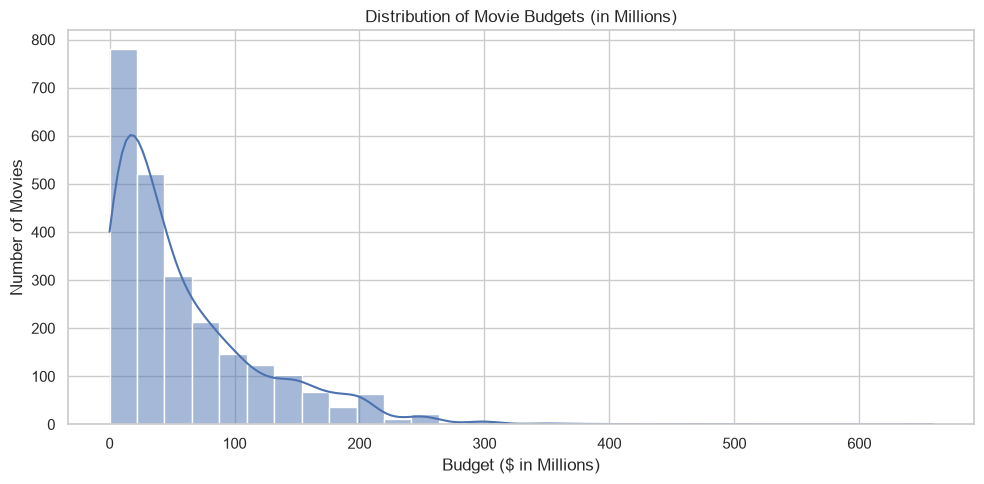

In [9]:
Movies['budget_millions'] = Movies['budget'] /1_000_000

plt.figure(figsize=(10, 5))

sns.histplot(
    data=Movies,
    x="budget_millions",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Budgets (in Millions)")
plt.xlabel("Budget ($ in Millions)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

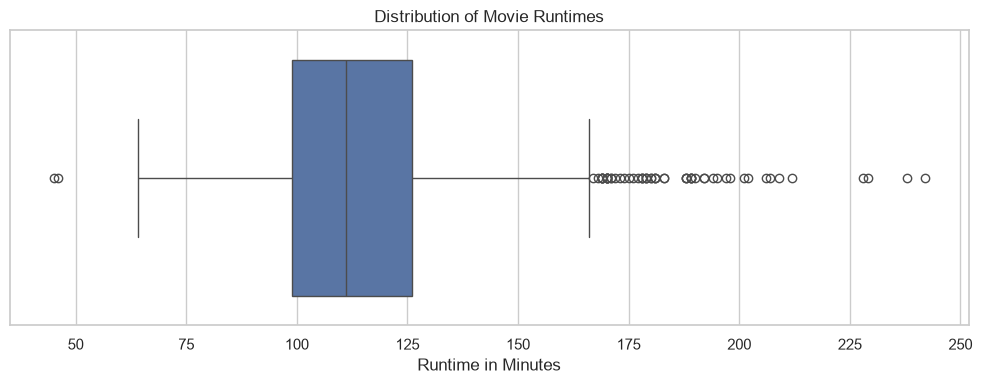

In [10]:
plt.figure(figsize=(10, 4))

sns.boxplot(data=Movies, x="runtime")

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime in Minutes")

plt.tight_layout()
plt.show()

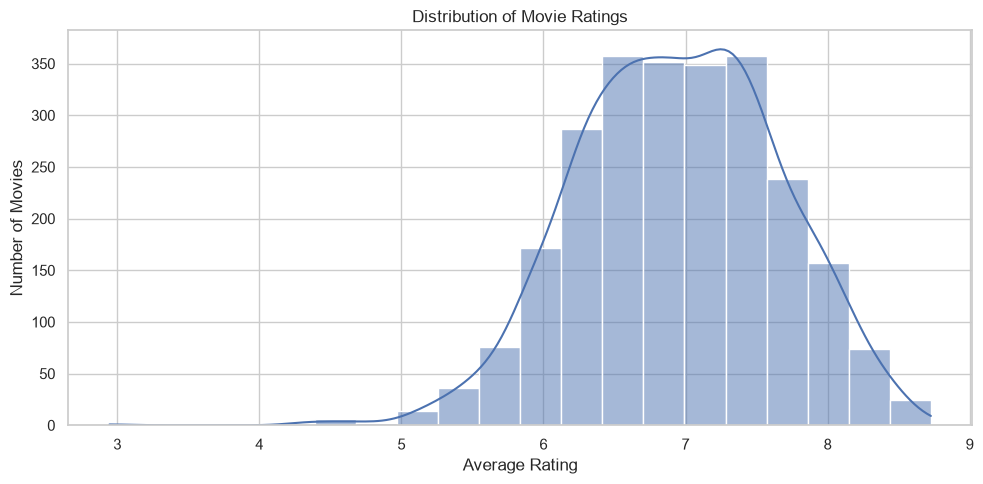

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=Movies,
    x="vote_average",
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

In [16]:
print("Movies:", Movies.columns.tolist())
print("Genres:", Genres.columns.tolist())
print("Movie_genres:", Movie_genres.columns.tolist())

Movies: ['movie_id', 'title', 'original_language', 'release_date', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'overview', 'day', 'month', 'year', 'budget_millions']
Genres: ['genre_id', 'genre_name']
Movie_genres: ['movie_id', 'genre_id']


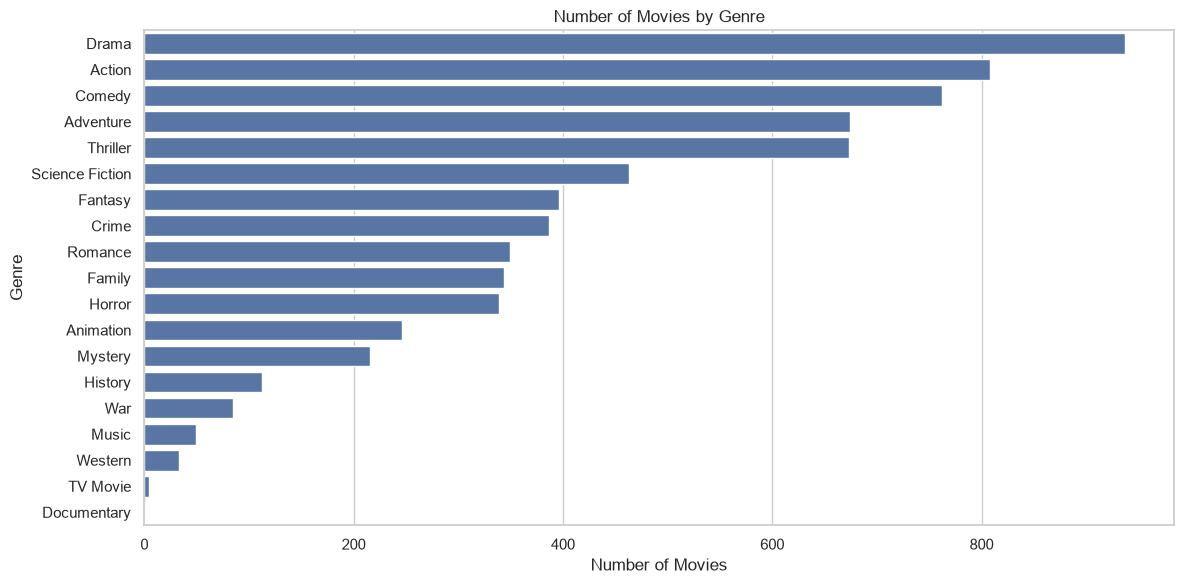

In [18]:
movie_genre_data = Movie_genres.merge(
    Genres,
    on="genre_id",
    how="left"
)


genre_counts = movie_genre_data.groupby(
    "genre_name"
)["movie_id"].nunique().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

Bivariate

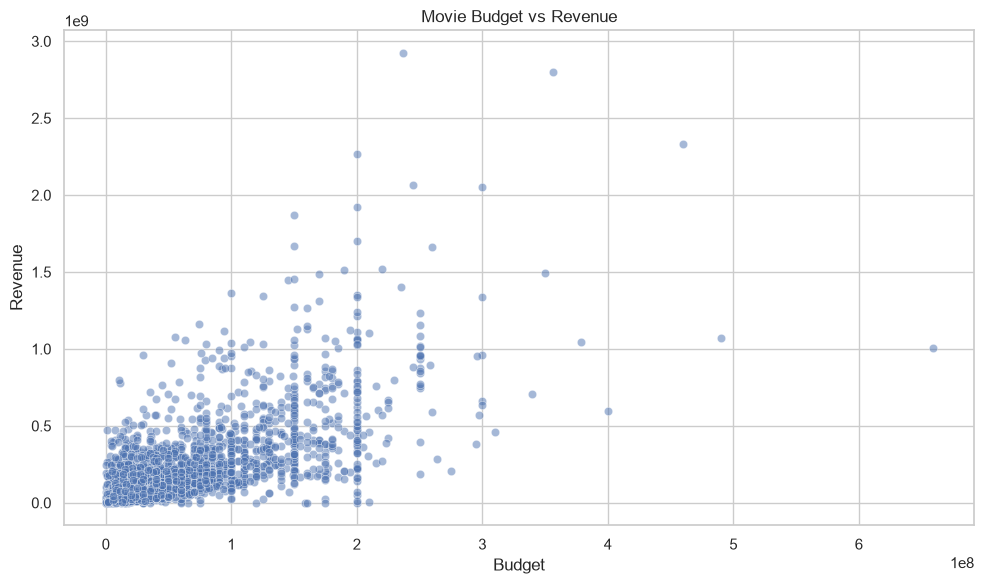

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=Movies,
    x="budget",
    y="revenue",
    alpha=0.5
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

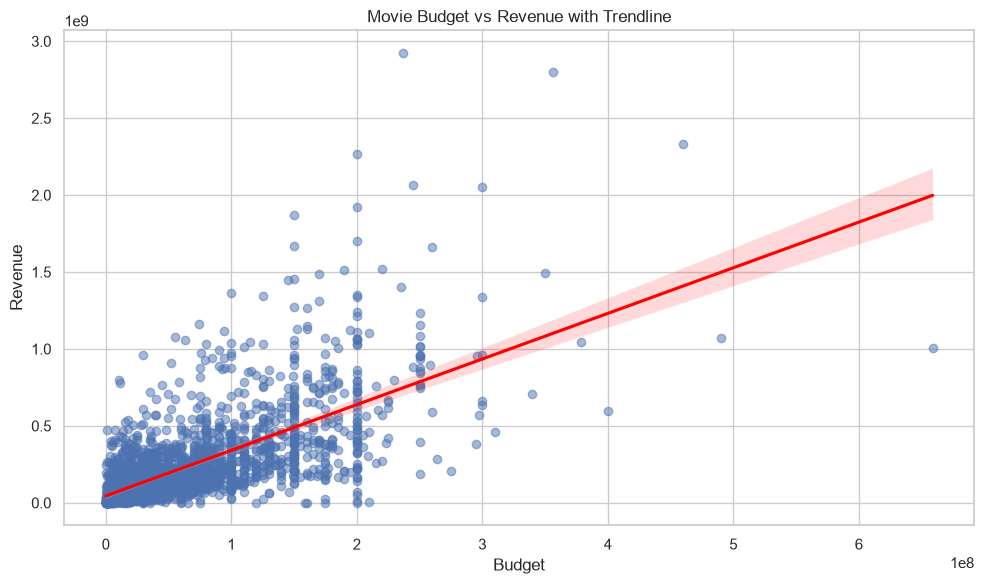

In [ ]:
plt.figure(figsize=(10, 6))


sns.regplot(
    data=Movies,
    x="budget",
    y="revenue",
    scatter_kws={'alpha': 0.5},     
    line_kws={'color': 'red'}         
)

plt.title("Movie Budget vs Revenue with Trendline")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

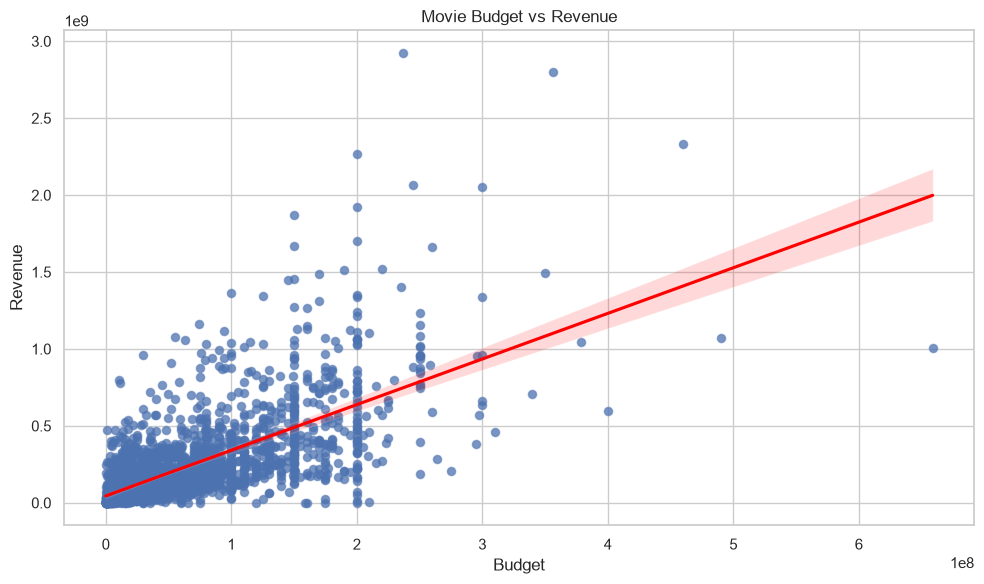

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=Movies,
    x="budget",
    y="revenue",
    alpha=0.5
)
sns.regplot(
    data=Movies,
    x="budget",
    y="revenue",
    scatter_kws={'alpha': 0.5},     
    line_kws={'color': 'red'}         
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

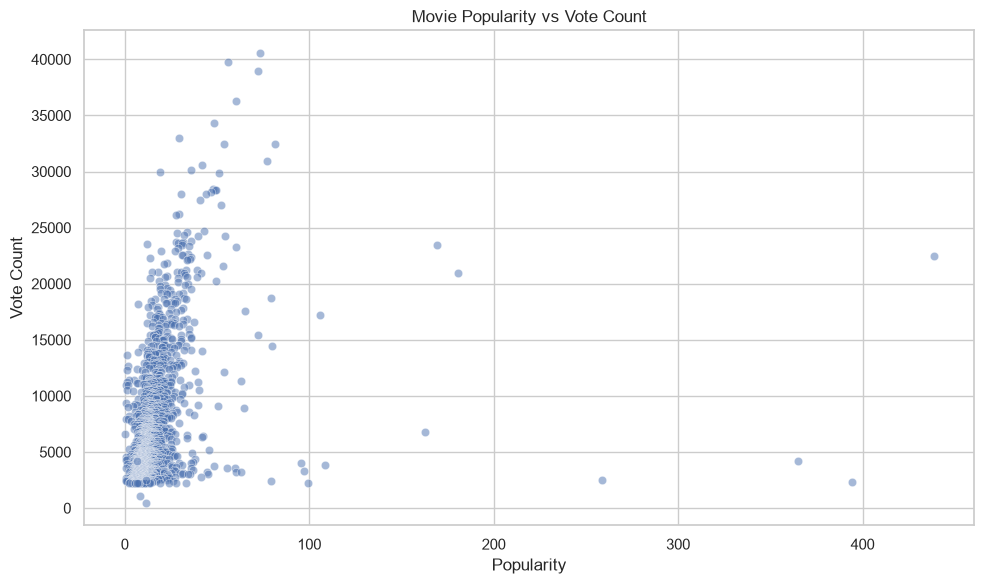

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=Movies,
    x="popularity",
    y="vote_count",
    alpha=0.5
)

plt.title("Movie Popularity vs Vote Count")
plt.xlabel("Popularity")
plt.ylabel("Vote Count")

plt.tight_layout()
plt.show()

In [28]:
movies_with_genres = Movies.merge(
    Movie_genres,
    on="movie_id",
    how="left"
)

movies_with_genres = movies_with_genres.merge(
    Genres,
    on="genre_id",
    how="left"
)



print(movies_with_genres[
    ["title", "genre_name", "vote_average"]
].head())

          title       genre_name  vote_average
0  Interstellar        Adventure         8.484
1  Interstellar            Drama         8.484
2  Interstellar  Science Fiction         8.484
3     Inception           Action         8.400
4     Inception  Science Fiction         8.400


In [29]:
print("Movies columns:")
print(Movies.columns.tolist())

print("Movie_genres columns:")
print(Movie_genres.columns.tolist())

print("Genres columns:")
print(Genres.columns.tolist())

Movies columns:
['movie_id', 'title', 'original_language', 'release_date', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'overview', 'day', 'month', 'year', 'budget_millions']
Movie_genres columns:
['movie_id', 'genre_id']
Genres columns:
['genre_id', 'genre_name']


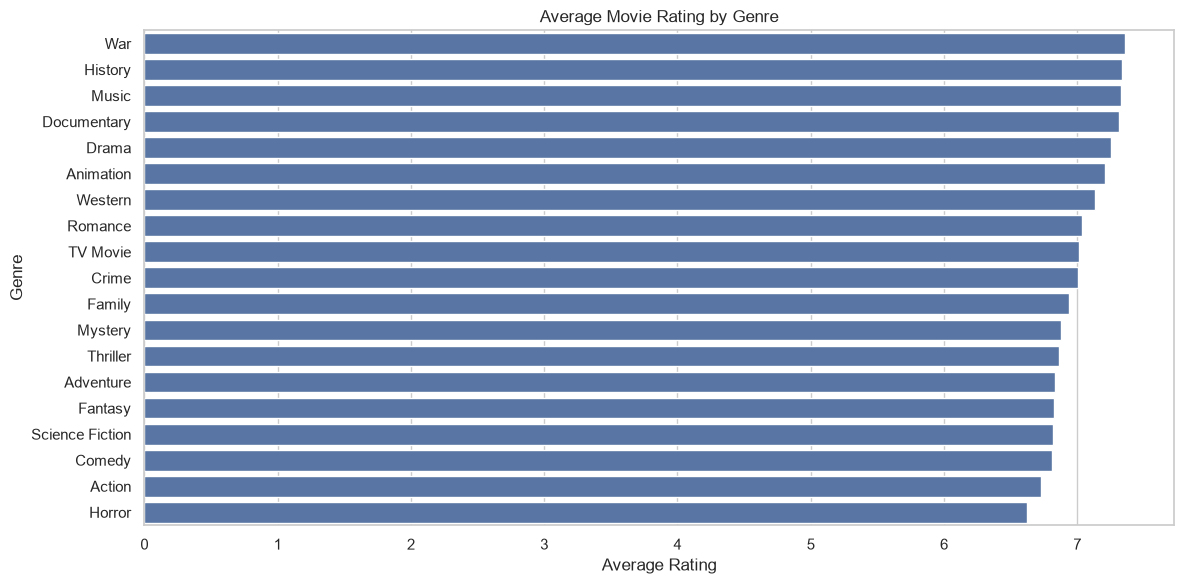

In [31]:
# Calculate average rating for each genre

genre_ratings = (
    movies_with_genres.groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=False)
)



plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_ratings.values,
    y=genre_ratings.index
)

plt.title("Average Movie Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

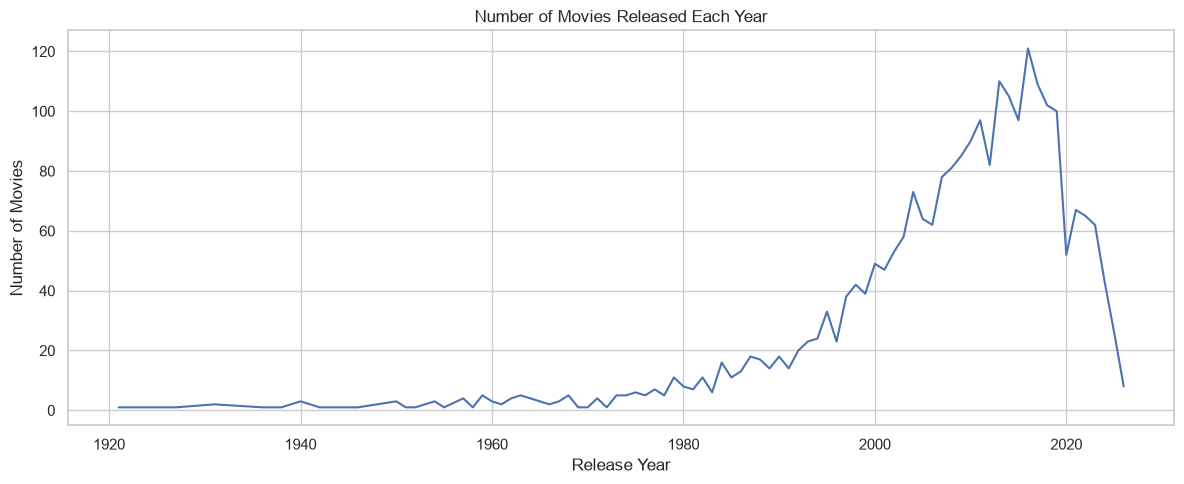

In [34]:
year_counts =Movies["year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))

plt.plot(year_counts.index, year_counts.values)

plt.title("Number of Movies Released Each Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

Multivariate

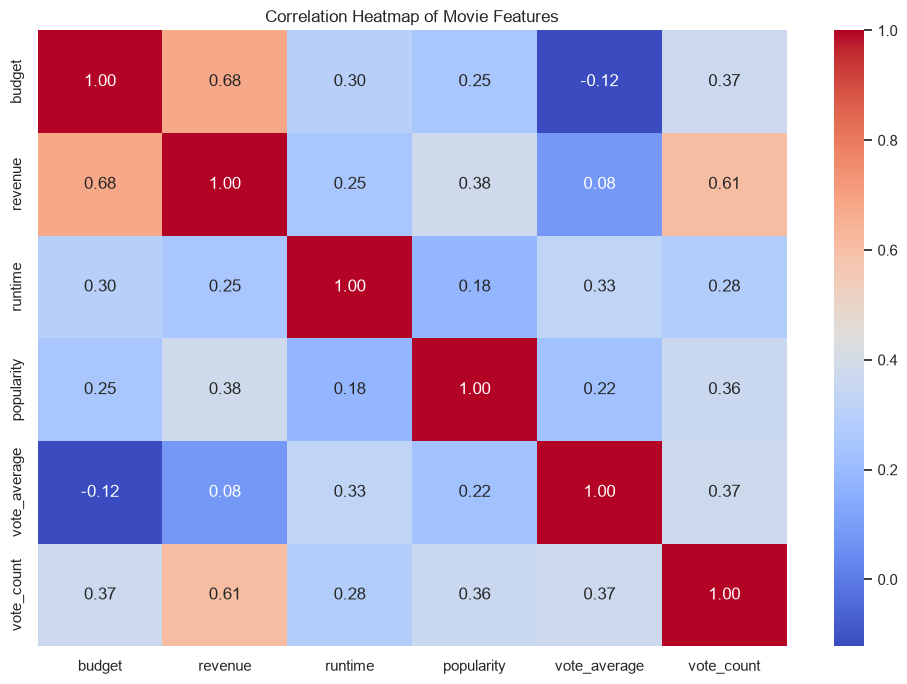

In [35]:
corr_columns = [
    "budget",
    "revenue",
    "runtime",
    "popularity",
    "vote_average",
    "vote_count"
]

corr_columns = [
    col for col in corr_columns
    if col in Movies.columns
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    Movies[corr_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Movie Features")

plt.tight_layout()
plt.show()

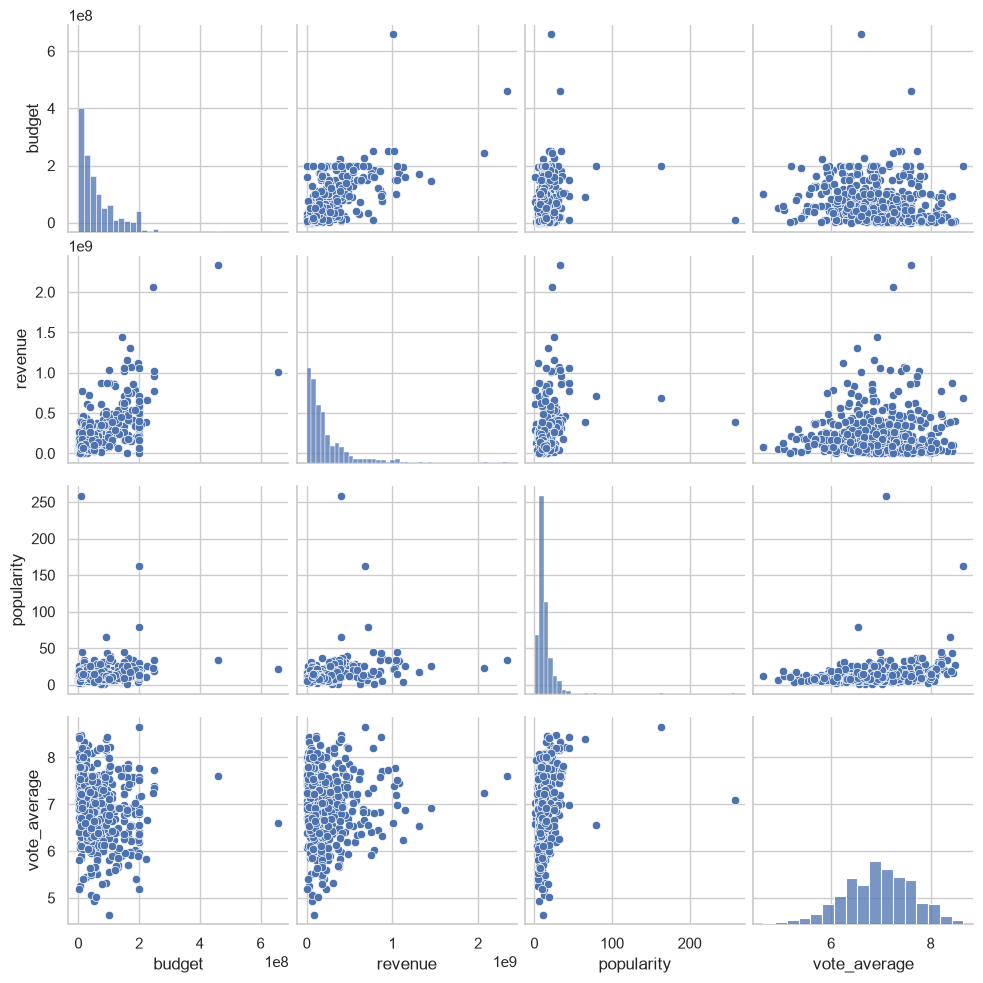

In [36]:
pair_columns = [
    "budget",
    "revenue",
    "popularity",
    "vote_average"
]

sns.pairplot(
    Movies[pair_columns].dropna().sample(
        n=min(500, len(Movies.dropna(subset=pair_columns))),
        random_state=42
    )
)

plt.show()

In [38]:
# Merge Movies with Movie_genres
movies_with_genres = Movies.merge(
    Movie_genres,
    on="movie_id",
    how="left"
)

# Merge with Genres to get genre names
movies_with_genres = movies_with_genres.merge(
    Genres,
    on="genre_id",
    how="left"
)

# Check the result
print(movies_with_genres[
    ["title", "budget", "revenue", "genre_name"]
].head())

          title       budget      revenue       genre_name
0  Interstellar  165000000.0  746606706.0        Adventure
1  Interstellar  165000000.0  746606706.0            Drama
2  Interstellar  165000000.0  746606706.0  Science Fiction
3     Inception  160000000.0  839030630.0           Action
4     Inception  160000000.0  839030630.0  Science Fiction


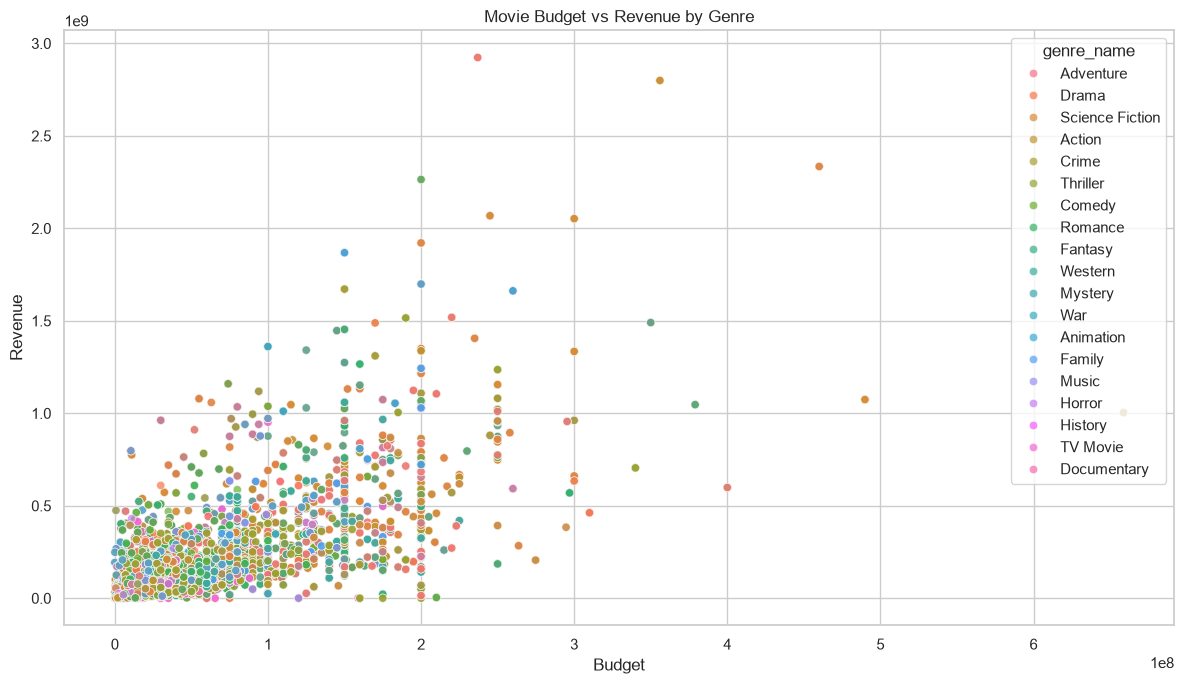

In [39]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=movies_with_genres,
    x="budget",
    y="revenue",
    hue="genre_name",
    alpha=0.7
)

plt.title("Movie Budget vs Revenue by Genre")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

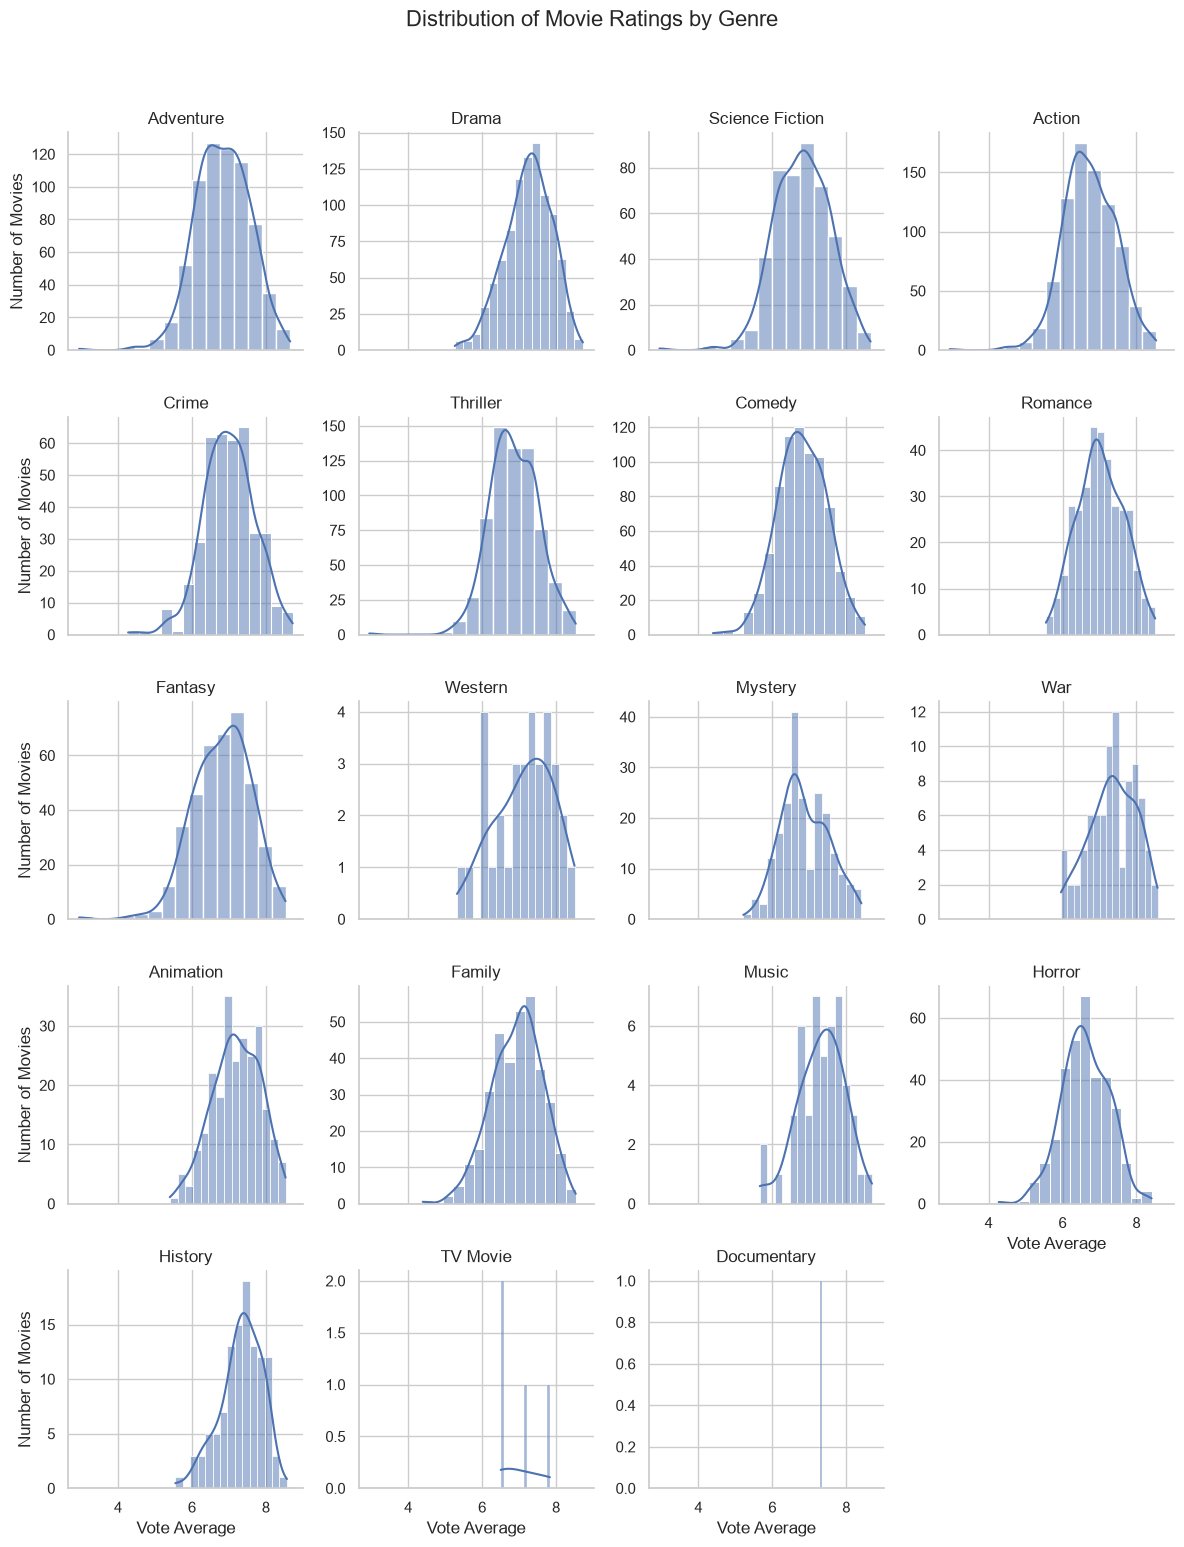

In [46]:
movies_with_genres = Movies.merge(
    Movie_genres,
    on="movie_id",
    how="inner"
)

movies_with_genres = movies_with_genres.merge(
    Genres,
    on="genre_id",
    how="left"
)

movies_with_genres["vote_average"] = pd.to_numeric(
    movies_with_genres["vote_average"],
    errors="coerce"
)

plot_data = movies_with_genres.dropna(
    subset=["vote_average", "genre_name"]
)

g = sns.FacetGrid(
    plot_data,
    col="genre_name",
    col_wrap=4,
    height=3,
    sharex=True,
    sharey=False
)

g.map_dataframe(
    sns.histplot,
    x="vote_average",
    bins=15,
    kde=True
)

g.set_axis_labels("Vote Average", "Number of Movies")
g.set_titles("{col_name}")
g.fig.suptitle(
    "Distribution of Movie Ratings by Genre",
    y=1.03,
    fontsize=16
)

plt.tight_layout()
plt.show()

In [42]:
movies_with_genres = Movies.merge(
    Movie_genres,
    on="movie_id",
    how="inner"
)

movies_with_genres = movies_with_genres.merge(
    Genres,
    on="genre_id",
    how="left"
)

print(movies_with_genres.columns.tolist())

['movie_id', 'title', 'original_language', 'release_date', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'overview', 'day', 'month', 'year', 'budget_millions', 'release_decade', 'genre_id', 'genre_name']


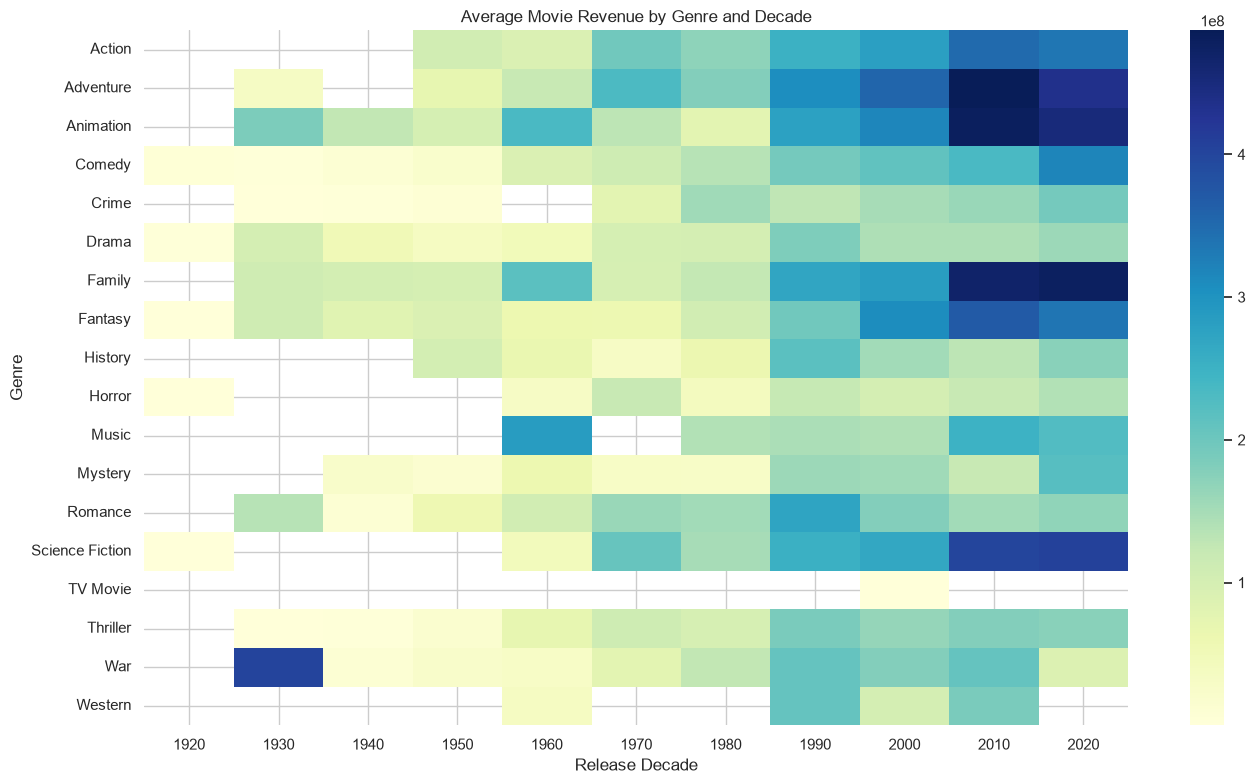

In [44]:
movies_with_genres["revenue"] = pd.to_numeric(
    movies_with_genres["revenue"],
    errors="coerce"
)

movies_with_genres["release_decade"] = (
    movies_with_genres["year"] // 10 * 10
)

revenue_pivot = movies_with_genres.pivot_table(
    index="genre_name",
    columns="release_decade",
    values="revenue",
    aggfunc="mean"
)

# Draw heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    revenue_pivot,
    cmap="YlGnBu",
    annot=False
)

plt.title("Average Movie Revenue by Genre and Decade")
plt.xlabel("Release Decade")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()